# 00 — Setup, tasks, and from-scratch baselines

This lab is a suite of small, CPU-friendly experiments that demonstrate
**what is known about transferability between tasks in neural networks**:
when reusing a trained network helps, when it hurts, and how tasks interact
when combined. Every later notebook compares against the from-scratch
baselines established here.

**The experimental universe.** Two real datasets (MNIST digits and
Fashion-MNIST clothing, both 28×28 grayscale so every model is
interchangeable) plus derived task variants: 5-class splits, rotated inputs,
a fixed pixel permutation, randomly shuffled labels, rotation-angle
prediction (a self-supervised pretext task), and a two-digit-sum task.
One shared architecture — a 5-block, ~200k-parameter, BatchNorm-free CNN —
is used everywhere so "transfer layer k" means the same thing in every
experiment.

**Why the baseline matters.** Neural networks are data-hungry: accuracy
climbs steeply with training-set size in the low-data regime. Transfer
learning's headline promise (Yosinski et al. 2014; Kornblith et al. 2019)
is to flatten that curve — most of its value concentrates exactly where
data is scarce. This notebook measures the scratch curve that all transfer
conditions must beat.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tllab").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import torch

import tllab
from tllab import analysis, data, models, train

tllab.setup()
print(f"SmallCNN parameters: {models.param_count(models.SmallCNN()):,}")

tllab: torch 2.13.0+cu130 | threads=4 | QUICK=False | root=/home/user/transfer-learning-lab
SmallCNN parameters: 197,482


## Datasets and derived tasks

Downloads happen here, up front (≈12 s), so any network problem fails fast
in this notebook rather than midway through the suite.

In [2]:
TASK_KEYS = ["mnist", "fashion", "mnist:rot90", "mnist:permuted",
             "mnist:randlabel", "mnist:rotpred"]
tasks = {k: data.get_task(k) for k in TASK_KEYS}
for t in tasks.values():
    print(t)

Task('mnist', 10 classes, train=60000, test=10000)
Task('fashion', 10 classes, train=60000, test=10000)
Task('mnist:rot90', 10 classes, train=60000, test=10000)
Task('mnist:permuted', 10 classes, train=60000, test=10000)
Task('mnist:randlabel', 10 classes, train=60000, test=10000)
Task('mnist:rotpred', 4 classes, train=60000, test=10000)


figure -> artifacts/figures/00_gallery.png


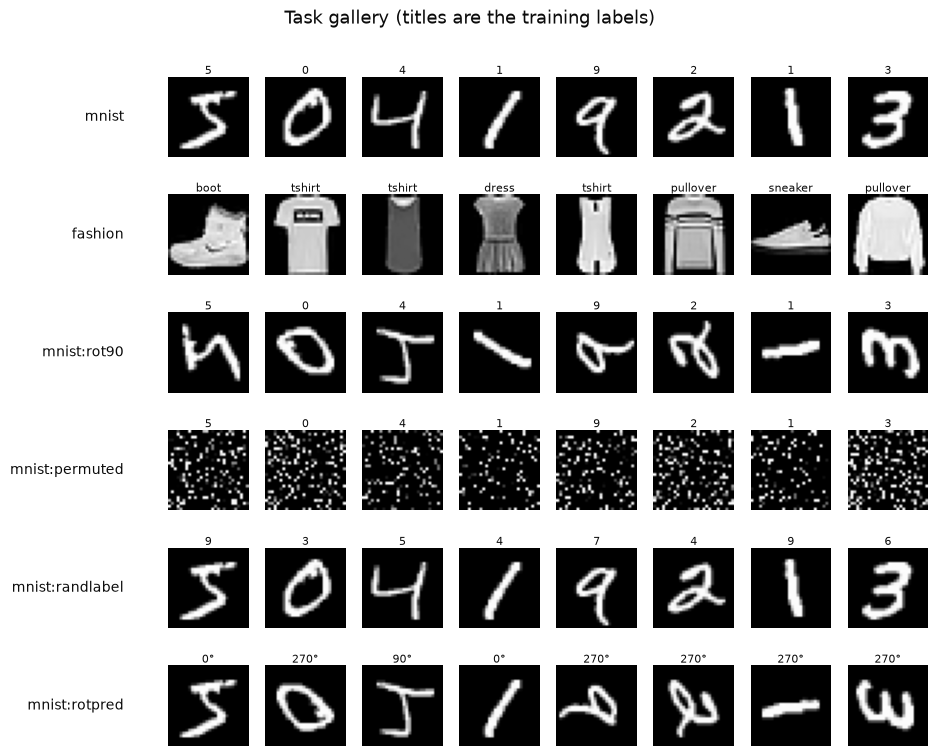

In [3]:
ROTPRED_NAMES = ["0°", "90°", "180°", "270°"]
N_COLS = 8
fig, axes = plt.subplots(len(TASK_KEYS), N_COLS, figsize=(9.5, 7.6))
for r, key in enumerate(TASK_KEYS):
    t = tasks[key]
    for c in range(N_COLS):
        ax = axes[r, c]
        ax.imshow(t.train_x[c, 0], cmap="gray")
        y = int(t.train_y[c])
        if key == "mnist:rotpred":
            label = ROTPRED_NAMES[y]
        elif key == "fashion":
            label = data.FASHION_CLASSES[y]
        else:
            label = str(y)
        ax.set_title(label, fontsize=8, pad=2)
        ax.axis("off")
    axes[r, 0].text(-0.55, 0.5, key, transform=axes[r, 0].transAxes,
                    ha="right", va="center", fontsize=10, color="#0b0b0b")
fig.suptitle("Task gallery (titles are the training labels)", y=1.0)
analysis.savefig("00_gallery")

Note the two *pathological* variants: `mnist:randlabel` pairs real images
with shuffled labels (the network can only memorize — Zhang et al. 2017
showed CNNs will happily do so), and `mnist:permuted` destroys all spatial
structure that convolutions exploit. Both reappear later as sources that
*hurt* transfer.

## From-scratch baselines vs training-set size

In [4]:
# Training-length schedule reused by later notebooks: more epochs (and smaller
# batches) at tiny n so every condition trains to convergence.
EPOCHS = {100: 30, 1000: 15, 10000: 8}
BATCH = {100: 32, 1000: 128, 10000: 128}


def scratch_baselines() -> pd.DataFrame:
    rows = []
    for key in ["mnist", "fashion"]:
        task = data.get_task(key)
        for n, epochs in EPOCHS.items():
            n_run, epochs = tllab.q(n, n // 10), tllab.q(epochs, 2)
            for seed in (tllab.seeds() if n <= 2000 else [0]):
                model = models.new_cnn(task.n_classes, seed)
                res = train.fit(model, data.subset(task, n_run, seed),
                                epochs=epochs, batch_size=BATCH[n], seed=seed)
                rows.append({"task": key, "n_train": n_run, "seed": seed,
                             "acc": res.final_acc, "wall_s": round(res.wall_s, 1)})
                print(f"  scratch {key} n={n_run} seed={seed}: {res.final_acc:.3f}")
    return pd.DataFrame(rows)


df = train.cached_sweep("00_scratch_baselines", scratch_baselines)
df.groupby(["task", "n_train"])["acc"].agg(["mean", "min", "max"])

[sweep cached] 00_scratch_baselines.csv


mean     min     max
task    n_train                          
fashion 100      0.648367  0.6297  0.6672
        1000     0.746600  0.7212  0.7637
        10000    0.851400  0.8514  0.8514
mnist   100      0.831033  0.8266  0.8398
        1000     0.935600  0.9293  0.9418
        10000    0.978100  0.9781  0.9781

figure -> artifacts/figures/00_scratch_vs_n.png


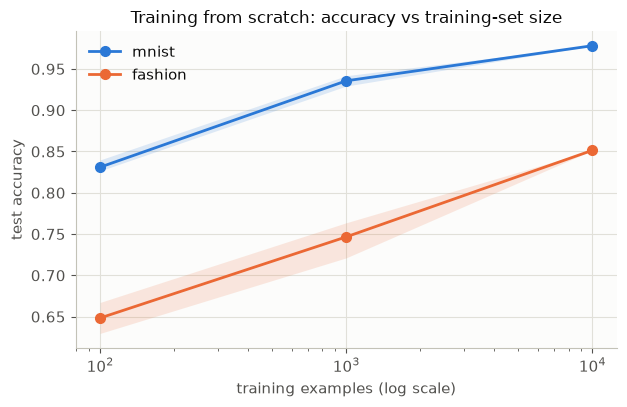

In [5]:
plt.figure(figsize=(6.4, 4.2))
analysis.plot_curves(df, x="n_train", y="acc", hue="task", logx=True,
                     ylabel="test accuracy",
                     title="Training from scratch: accuracy vs training-set size")
plt.gca().set_xlabel("training examples (log scale)")
analysis.savefig("00_scratch_vs_n")

## Shared source checkpoints

The two standard source models (trained on 20k examples for 6 epochs) are
saved under `artifacts/checkpoints/` — every later notebook loads them via
`train_or_load_source` instead of retraining, which is what makes each
notebook independently re-runnable.

In [6]:
src_mnist = train.train_or_load_source("mnist")
src_fashion = train.train_or_load_source("fashion")

[ckpt cached] mnist: test_acc=0.985
[ckpt cached] fashion: test_acc=0.864


## Takeaways

- Accuracy climbs steeply with data in the low-data regime and saturates:
  the gap between n=100 and n=10,000 is tens of points on both datasets.
  **This low-data region is where transfer learning has room to pay off.**
- Fashion-MNIST is the harder dataset (lower accuracy at every n) — worth
  remembering when comparing cross-dataset transfer directions later.

**References.** Yosinski, Clune, Bengio & Lipson, *How transferable are
features in deep neural networks?* (NeurIPS 2014). Kornblith, Shlens & Le,
*Do better ImageNet models transfer better?* (CVPR 2019). Zhang et al.,
*Understanding deep learning requires rethinking generalization* (ICLR 2017).

In [7]:
m = df.groupby(["task", "n_train"])["acc"].mean()
if not tllab.config.QUICK:
    analysis.claim("scratch mnist@10k > 0.95", m["mnist"][10000] > 0.95,
                   f"got {m['mnist'][10000]:.3f}", hard=True)
    analysis.claim("scratch fashion@10k > 0.82", m["fashion"][10000] > 0.82,
                   f"got {m['fashion'][10000]:.3f}", hard=True)
    analysis.claim("low-data regime is steep (mnist@10k − mnist@100 > 10 pts)",
                   m["mnist"][10000] - m["mnist"][100] > 0.10,
                   f"gap = {m['mnist'][10000] - m['mnist'][100]:.3f}", hard=True)

CLAIM CHECK [PASS] scratch mnist@10k > 0.95 — got 0.978
CLAIM CHECK [PASS] scratch fashion@10k > 0.82 — got 0.851
CLAIM CHECK [PASS] low-data regime is steep (mnist@10k − mnist@100 > 10 pts) — gap = 0.147
